# EDA round 2: what actually makes this problem hard

Round 1 (`eda.ipynb`) characterised the data. This round goes after the *structure of the
prediction problem itself*, aimed at motivating features and architecture rather than describing
distributions. Each section ends with the concrete feature or design implication.


In [1]:
import sys, re, warnings
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASE,
    "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "grid.color": GRID,
    "axes.grid": True, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 11, "figure.dpi": 110,
})

uc = pd.read_csv("../../data/kernel/Unit_commitment_decisions.csv").sort_values("Run No").reset_index(drop=True)
uc["starttime"] = pd.to_datetime(uc["starttime"])
label_cols = [c for c in uc.columns if c.startswith("result_committed_")]
units_raw = sorted({re.match(r"result_committed_(.+)_t\d+$", c).group(1) for c in label_cols})
san = lambda u: u.replace(" ", "_")
units = [san(u) for u in units_raw]
M = {san(u): uc[[f"result_committed_{u}_t{t}" for t in range(168)]].to_numpy() for u in units_raw}

train = pd.read_parquet("../../data/processed/train_hourly.parquet")
train["year"] = train["starttime"].dt.year
with open("../../data/extended/Tokke_Vinje_topology.yaml") as f:
    topo = yaml.safe_load(f)
print(f"{len(units)} units, {len(uc)} labelled cases")


14 units, 2922 labelled cases


## 1. The optimizer disagrees with itself

Cases are daily rolling: case *N* starts one day before case *N+1*, so they overlap on 144
identical wall-clock hours (case *N*'s hour 24+h is the same real timestamp as case *N+1*'s hour
h). Both were solved by SHOP from essentially the same physical state. Do they agree?


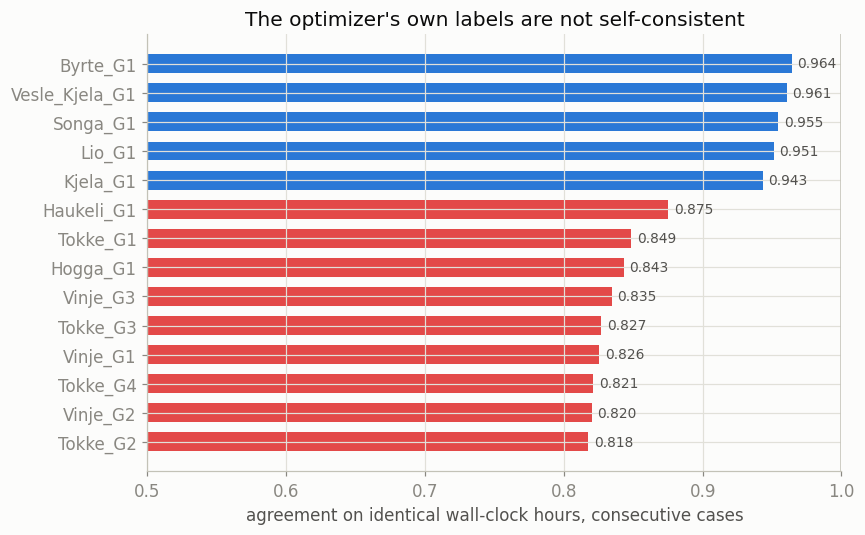

Overall agreement: 0.878  (i.e. ~12% of labels flip)


In [2]:
agree = {}
for u in units:
    A = M[u][:-1, 24:168]     # case N,   hours 24..167
    B = M[u][1:, 0:144]       # case N+1, hours 0..143  (same wall clock)
    agree[u] = (A == B).mean()
agree = pd.Series(agree).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = [CAT[7] if v < 0.9 else CAT[0] for v in agree.values]
ax.barh(agree.index, agree.values, color=colors, height=0.65)
ax.set_xlim(0.5, 1.0)
ax.axvline(1.0, color=BASE, lw=1)
ax.set_xlabel("agreement on identical wall-clock hours, consecutive cases")
ax.set_title("The optimizer's own labels are not self-consistent")
for y, v in enumerate(agree.values):
    ax.text(v + 0.004, y, f"{v:.3f}", va="center", fontsize=9, color=INK_SECONDARY)
plt.tight_layout(); plt.show()

print(f"Overall agreement: {agree.mean():.3f}  (i.e. ~{(1-agree.mean())*100:.0f}% of labels flip)")


**Finding 1.** The same physical hour, re-solved one day later with a different 168-hour horizon,
gets a **different commitment decision 12% of the time overall — and ~18% for the Tokke and
Vinje units**. This is not measurement noise; it's the optimizer responding to end-of-horizon
boundary conditions that a model indexed on wall-clock features cannot observe. It is an
effective ceiling on achievable accuracy.


## 2. That self-inconsistency is almost the whole story of per-unit difficulty

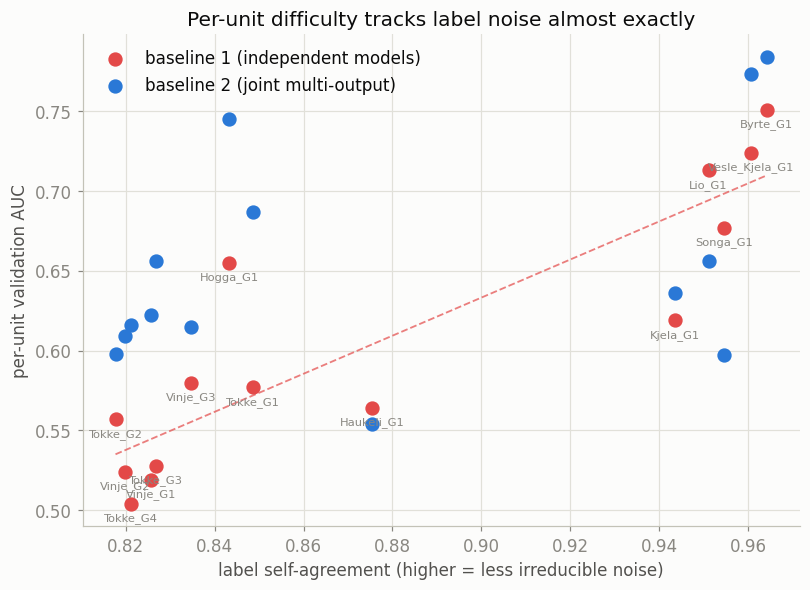

corr(self_agreement, baseline1 AUC) = 0.881
corr(self_agreement, baseline2 AUC) = 0.416


In [3]:
baseline1 = pd.Series({"Byrte_G1":0.751,"Vesle_Kjela_G1":0.724,"Lio_G1":0.713,"Songa_G1":0.677,
    "Hogga_G1":0.655,"Kjela_G1":0.619,"Vinje_G3":0.580,"Tokke_G1":0.577,"Haukeli_G1":0.564,
    "Tokke_G2":0.557,"Tokke_G3":0.528,"Vinje_G2":0.524,"Vinje_G1":0.519,"Tokke_G4":0.504})
baseline2 = pd.Series({"Byrte_G1":0.784,"Vesle_Kjela_G1":0.773,"Hogga_G1":0.745,"Tokke_G1":0.687,
    "Lio_G1":0.656,"Tokke_G3":0.656,"Kjela_G1":0.636,"Vinje_G1":0.622,"Tokke_G4":0.616,
    "Vinje_G3":0.615,"Vinje_G2":0.609,"Tokke_G2":0.598,"Songa_G1":0.597,"Haukeli_G1":0.554})

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(agree, baseline1[agree.index], s=70, color=CAT[7], label="baseline 1 (independent models)", zorder=3)
ax.scatter(agree, baseline2[agree.index], s=70, color=CAT[0], label="baseline 2 (joint multi-output)", zorder=3)
for u in agree.index:
    ax.annotate(u, (agree[u], baseline1[u]), fontsize=7.5, color=INK_MUTED,
                xytext=(0, -11), textcoords="offset points", ha="center")
z = np.polyfit(agree, baseline1[agree.index], 1)
xs = np.linspace(agree.min(), agree.max(), 50)
ax.plot(xs, np.polyval(z, xs), color=CAT[7], lw=1.2, ls="--", alpha=0.7, zorder=2)
ax.set_xlabel("label self-agreement (higher = less irreducible noise)")
ax.set_ylabel("per-unit validation AUC")
ax.set_title("Per-unit difficulty tracks label noise almost exactly")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

print(f"corr(self_agreement, baseline1 AUC) = {agree.corr(baseline1[agree.index]):.3f}")
print(f"corr(self_agreement, baseline2 AUC) = {agree.corr(baseline2[agree.index]):.3f}")


**Finding 2.** Label self-agreement correlates **r = 0.88** with baseline-1 per-unit AUC — roughly
**78% of the variance in per-unit difficulty is explained by how self-consistent the labels
are**, not by anything about our features. Crucially, that correlation *drops to 0.42* for the
joint multi-output model: pooling across correlated units is precisely what let the noisy
Tokke/Vinje units borrow signal and break the dependence on their own noisy labels. That also
explains why the clean, low-noise units (Songa_G1, Lio_G1) got *worse* under joint modelling —
they had good signal of their own and were pooled with seven noisy units.


## 3. Units inside a plant are physically identical — and strictly merit-ordered

In [4]:
gens = topo["model"]["generator"]
spec_tbl = pd.DataFrame({g: {k: gens[g][k] for k in ("p_min", "p_max", "p_nom")}
                          for g in ["Tokke_G1","Tokke_G2","Tokke_G3","Tokke_G4",
                                    "Vinje_G1","Vinje_G2","Vinje_G3"]}).T
print("Generator specs (from the topology YAML we previously weren't using):")
print(spec_tbl.to_string())


Generator specs (from the topology YAML we previously weren't using):
          p_min  p_max  p_nom
Tokke_G1   36.9  107.5  107.5
Tokke_G2   36.9  107.5  107.5
Tokke_G3   36.9  107.5  107.5
Tokke_G4   36.9  107.5  107.5
Vinje_G1   34.4  100.0  100.0
Vinje_G2   34.4  100.0  100.0
Vinje_G3   34.4  100.0  100.0


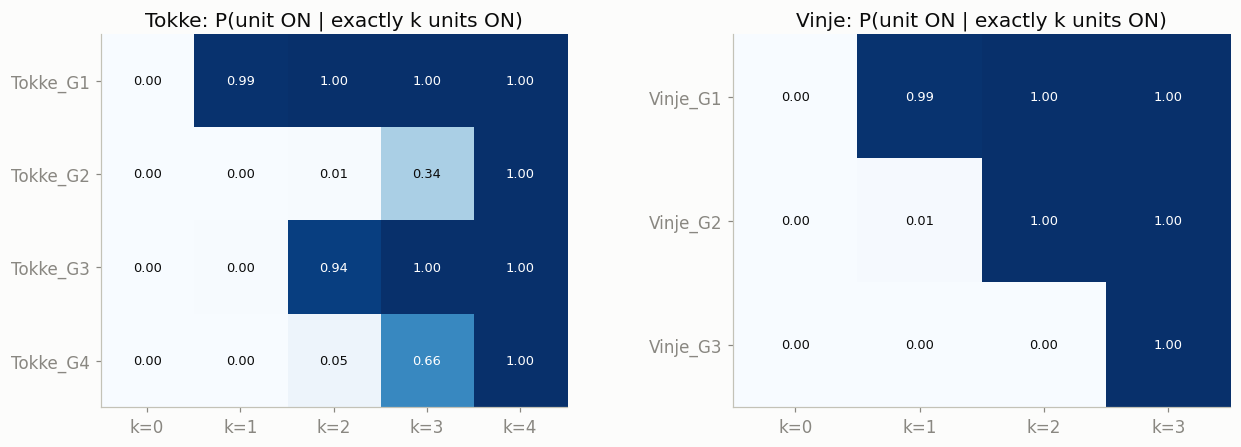

Tokke: knowing only the COUNT predicts the exact on/off pattern correctly 97.8% of the time
Vinje: knowing only the COUNT predicts the exact on/off pattern correctly 99.9% of the time


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
summary = {}
for ax, (plant, gu) in zip(axes, [("Tokke", ["Tokke_G1","Tokke_G2","Tokke_G3","Tokke_G4"]),
                                    ("Vinje", ["Vinje_G1","Vinje_G2","Vinje_G3"])]):
    stack = np.stack([M[g].ravel() for g in gu])
    n_on = stack.sum(axis=0)
    grid = np.zeros((len(gu), len(gu) + 1))
    for k in range(len(gu) + 1):
        m = n_on == k
        if m.sum():
            grid[:, k] = [stack[i][m].mean() for i in range(len(gu))]
    im = ax.imshow(grid, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(gu) + 1), [f"k={k}" for k in range(len(gu) + 1)])
    ax.set_yticks(range(len(gu)), gu)
    ax.grid(False)
    ax.set_title(f"{plant}: P(unit ON | exactly k units ON)")
    for i in range(len(gu)):
        for j in range(len(gu) + 1):
            ax.text(j, i, f"{grid[i,j]:.2f}", ha="center", va="center", fontsize=8.5,
                    color="white" if grid[i, j] > 0.55 else INK)
    # exact-pattern accuracy from count alone
    patterns = np.array(["".join(map(str, stack[:, i])) for i in range(stack.shape[1])])
    correct = sum(np.unique(patterns[n_on == k], return_counts=True)[1].max()
                  for k in range(len(gu) + 1) if (n_on == k).sum())
    summary[plant] = correct / len(patterns)
plt.tight_layout(); plt.show()

for p, a in summary.items():
    print(f"{p}: knowing only the COUNT predicts the exact on/off pattern correctly {a:.1%} of the time")


**Finding 3.** Every generator inside a plant is **physically identical** (Tokke: 4x p_max=107.5
MW; Vinje: 3x p_max=100 MW). The commitment follows a near-strict merit order — Vinje is
G1 -> G1+G2 -> all; Tokke is G1 -> G1+G3 -> then G4 or G2. Consequently **knowing only how many
units are on at a plant predicts exactly which ones with 97.8% (Tokke) / 99.9% (Vinje)
accuracy**.

**Finding 4.** Because the machines are interchangeable, *which* identical unit the solver picks
for the marginal slot is partly an arbitrary tie-break — which is the mechanism behind the
18% label inconsistency in Finding 1. The only genuinely ambiguous slot is Tokke's third
(G2 vs G4, 34/66).

> **Design implication (the big one).** The 14-output problem is really a small number of
> *per-plant count* problems plus a near-deterministic lookup. Predicting counts (ordinal, and
> far less noisy) and then expanding via merit order is a fundamentally better-posed target than
> predicting 14 individually-noisy binaries.


## 4. How much does each unit actually move?

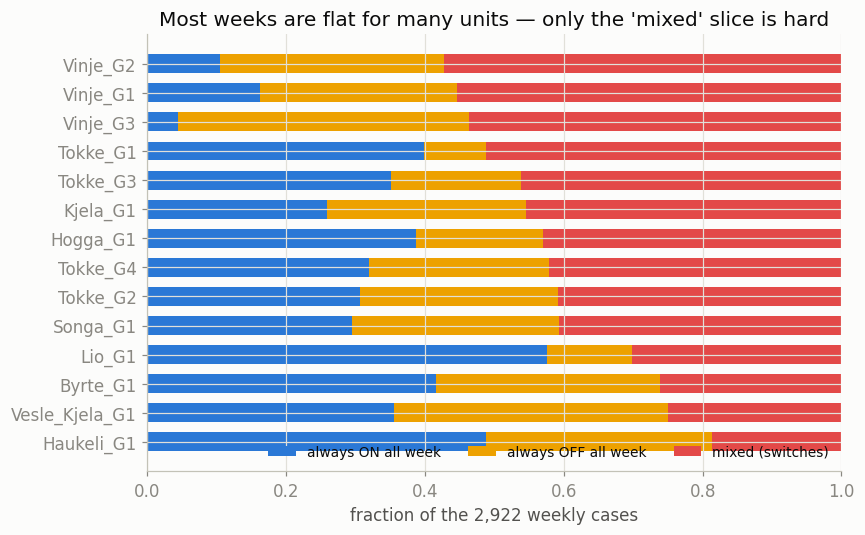

                toggles_per_week  always_on  always_off  mixed
unit                                                          
Haukeli_G1                 0.494      0.488       0.325  0.187
Vesle_Kjela_G1             0.748      0.356       0.394  0.251
Byrte_G1                   0.988      0.415       0.323  0.262
Lio_G1                     1.171      0.576       0.123  0.302
Songa_G1                   2.025      0.294       0.299  0.407
Tokke_G2                   1.957      0.306       0.286  0.408
Tokke_G4                   2.118      0.320       0.259  0.421
Hogga_G1                   1.718      0.387       0.183  0.430
Kjela_G1                   2.331      0.259       0.287  0.454
Tokke_G3                   2.515      0.351       0.187  0.462
Tokke_G1                   3.015      0.398       0.089  0.512
Vinje_G3                   3.605      0.044       0.419  0.537
Vinje_G1                   3.019      0.162       0.283  0.554
Vinje_G2                   3.323      0.104       0.323

In [6]:
rows = []
for u in units:
    A = M[u]
    rows.append({"unit": u,
                 "toggles_per_week": np.abs(np.diff(A, axis=1)).sum(axis=1).mean(),
                 "always_on": (A.sum(axis=1) == 168).mean(),
                 "always_off": (A.sum(axis=1) == 0).mean()})
sw = pd.DataFrame(rows).set_index("unit")
sw["mixed"] = 1 - sw["always_on"] - sw["always_off"]
sw = sw.sort_values("mixed")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(sw.index, sw["always_on"], color=CAT[0], height=0.65, label="always ON all week")
ax.barh(sw.index, sw["always_off"], left=sw["always_on"], color=CAT[3], height=0.65, label="always OFF all week")
ax.barh(sw.index, sw["mixed"], left=sw["always_on"] + sw["always_off"], color=CAT[7], height=0.65, label="mixed (switches)")
ax.set_xlim(0, 1); ax.set_xlabel("fraction of the 2,922 weekly cases")
ax.set_title("Most weeks are flat for many units — only the 'mixed' slice is hard")
ax.legend(frameon=False, ncol=3, loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()
print(sw.round(3).to_string())


**Finding 5.** For many units most weeks are completely flat: Haukeli_G1 never switches in
**81%** of weeks, Vesle_Kjela_G1 in 75%, Byrte_G1 in 74%. Only the "mixed" slice is genuinely
hard. Vinje_G3 is the busiest (3.6 toggles/week, mixed in 54% of weeks).

> **Feature implication.** A case-level "will this unit move at all this week?" signal is a
> different and much easier question than the hour-level one, and it partitions the problem:
> flat weeks need only a level prediction, mixed weeks need the hourly shape.


## 5. Feature-level findings: what's dead, what's mis-specified, what works

In [7]:
feat = [c for c in train.columns if c.startswith(("storage_", "water_value_", "inflow_", "price_"))]
nun = train[feat].nunique().sort_values()
print("Constant (zero-information) feature columns:", nun[nun <= 1].index.tolist())
print("\n(Both are documented in the dataset PDF as having no historical record and being")
print(" assumed 50% full — so they were never real features to begin with.)")

res_specs = topo["model"]["reservoir"]
vols = pd.Series({r: s["max_vol"] for r, s in res_specs.items()}).sort_values()
print(f"\nReservoir max_vol spans {vols.min()} to {vols.max()} Mm3 ({vols.max()/vols.min():.0f}x range)")


Constant (zero-information) feature columns: ['storage_Vatjern', 'storage_Hyljelihyl']

(Both are documented in the dataset PDF as having no historical record and being
 assumed 50% full — so they were never real features to begin with.)

Reservoir max_vol spans 0.26 to 640.0 Mm3 (2462x range)


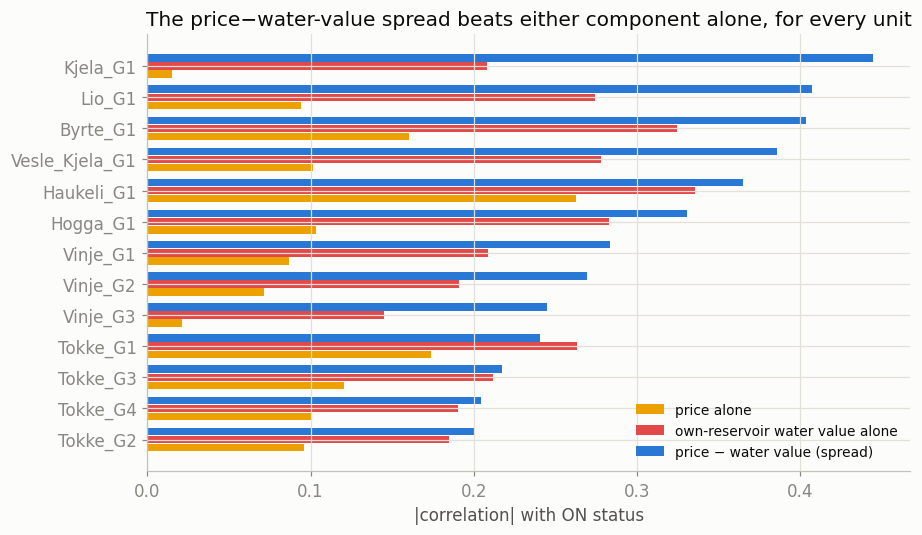

                    reservoir  |corr| storage  |corr| water_value  |corr| price  |corr| price - water_value
unit                                                                                                       
Tokke_G2            Vinjevatn           0.190               0.185         0.096                       0.201
Tokke_G4            Vinjevatn           0.190               0.190         0.100                       0.205
Tokke_G3            Vinjevatn           0.193               0.212         0.121                       0.217
Tokke_G1            Vinjevatn           0.198               0.263         0.174                       0.241
Vinje_G3           Vaamarvatn           0.150               0.145         0.021                       0.245
Vinje_G2           Vaamarvatn           0.165               0.191         0.071                       0.270
Vinje_G1           Vaamarvatn           0.173               0.209         0.087                       0.283
Hogga_G1               Banda

In [8]:
# Does the price-minus-water-value spread beat its components, per unit?
plant_res = {c["to"]: c["from"] for c in topo["connections"]
             if c["to_type"] == "plant" and c["from_type"] == "reservoir"}
rows = []
for u in units:
    plant = u.rsplit("_G", 1)[0]
    r = plant_res.get(plant) or plant_res.get(plant.replace("_", " "))
    if r is None:
        continue
    y = train[f"on_{u}"]
    rows.append({"unit": u, "reservoir": r,
                 "|corr| storage": abs(y.corr(train[f"storage_{r}"])),
                 "|corr| water_value": abs(y.corr(train[f"water_value_{r}"])),
                 "|corr| price": abs(y.corr(train["price_eur_mwh"])),
                 "|corr| price - water_value": abs(y.corr(train["price_eur_mwh"] - train[f"water_value_{r}"]))})
spread = pd.DataFrame(rows).set_index("unit").sort_values("|corr| price - water_value")

fig, ax = plt.subplots(figsize=(8.5, 5))
y = np.arange(len(spread))
ax.barh(y - 0.26, spread["|corr| price"], height=0.24, color=CAT[3], label="price alone")
ax.barh(y,        spread["|corr| water_value"], height=0.24, color=CAT[7], label="own-reservoir water value alone")
ax.barh(y + 0.26, spread["|corr| price - water_value"], height=0.24, color=CAT[0], label="price − water value (spread)")
ax.set_yticks(y, spread.index)
ax.set_xlabel("|correlation| with ON status")
ax.set_title("The price−water-value spread beats either component alone, for every unit")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()
print(spread.round(3).to_string())


**Finding 6.** Two of our 53 features — `storage_Vatjern` and `storage_Hyljelihyl` — are
**literally constant** and carry zero information (the dataset documentation notes these two
reservoirs have no historical record and were assumed 50% full).

**Finding 7.** The **`price − own-reservoir water value` spread** has a stronger absolute
correlation with ON status than either price or water value alone, **for every mapped unit** —
the clearest single feature-engineering win available. This is the classic hydropower "sell now
vs. store it" signal, and it is not currently in the feature set.

**Finding 8 (a correction).** Normalising storage by each reservoir's `max_vol` — which I
previously suggested was an important miss — is a **no-op for tree models**: it is a monotonic
per-feature rescale, and trees are invariant to those. The 2462x spread in reservoir size only
matters for features that *combine* reservoirs (e.g. system-wide percent-full), or for linear /
neural models. Worth stating explicitly so we don't "fix" a non-problem.


## 6. The series is badly non-stationary, per unit

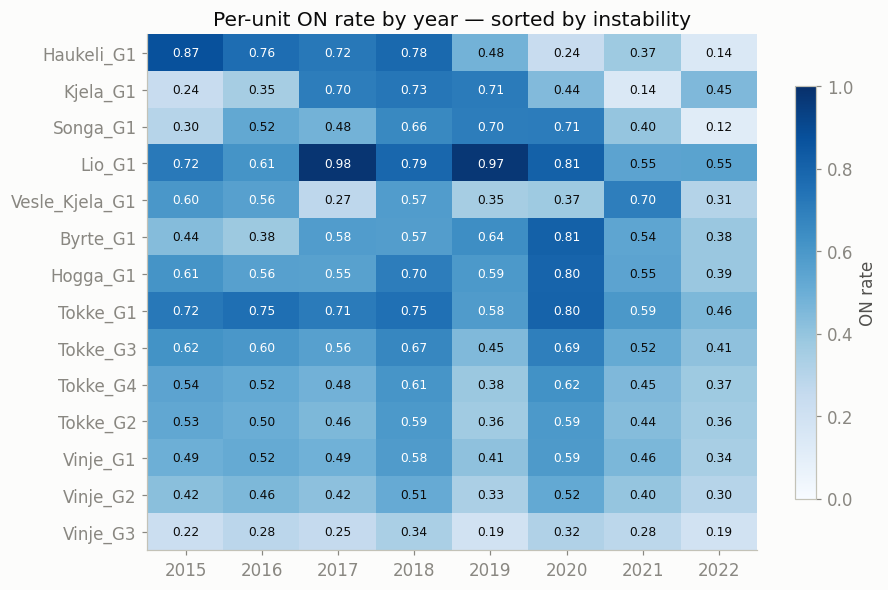

In [9]:
target_cols = [f"on_{u}" for u in units]
yearly = train.groupby("year")[target_cols].mean().T
yearly.index = [i[3:] for i in yearly.index]
yearly = yearly.loc[yearly.std(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8.5, 5.5))
im = ax.imshow(yearly.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(yearly.columns)), yearly.columns)
ax.set_yticks(range(len(yearly)), yearly.index)
ax.grid(False)
for i in range(len(yearly)):
    for j in range(len(yearly.columns)):
        v = yearly.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.55 else INK)
ax.set_title("Per-unit ON rate by year — sorted by instability")
fig.colorbar(im, ax=ax, shrink=0.8, label="ON rate")
plt.tight_layout(); plt.show()


**Finding 9.** Several units are severely non-stationary. **Haukeli_G1 collapses from 0.87 (2015)
to 0.14 (2022)**; Songa_G1 swings 0.30 -> 0.71 -> 0.12. These are structural shifts in how the
plant is operated, not noise. Any model trained on 2015–2021 is fitting a regime that no longer
holds — and our test period is 2023–2024, further out still. This argues for recency weighting
or training on a shorter recent window, and it is a stronger effect than the 2022 price spike we
flagged in round 1.


## 7. Extended data: what's actually usable

In [10]:
mv = pd.read_csv("../../data/extended/Constraint_min_volume.csv")
mf = pd.read_csv("../../data/extended/Constraint_min_flow.csv")
for name, df in [("min_volume", mv), ("min_flow", mf)]:
    df["date"] = pd.to_datetime(df["date"]).dt.tz_localize(None)
    cols = [c for c in df.columns if c != "date"]
    frac = (df[cols] > 0).mean()
    print(f"{name}: fraction of hours with constraint > 0")
    print(frac[frac > 0].round(3).to_string())
    act = (df[cols] > 0).any(axis=1).groupby(df["date"].dt.month).mean()
    print(f"  months where any constraint is active: {[m for m, v in act.items() if v > 0.5]}\n")

print("Songa has NO direct reservoir->plant edge; it is fed via two tunnels:")
for c in topo["connections"]:
    if c["to"] == "Songa" and c["from_type"] == "tunnel":
        print("  ", c["from"], "(tunnel) -> Songa")


min_volume: fraction of hours with constraint > 0
Totak        0.339
Byrtevatn    0.126
Staavatn     0.255
  months where any constraint is active: [7, 8, 9, 10]



min_flow: fraction of hours with constraint > 0
b_Kjelavatn          1.000
b_Hyljelihyl         1.000
b_Vinjevatn          1.000
b_Byrtevatn          0.339
b_Bandak             1.000
r_Vest_Vassdraget    1.000
  months where any constraint is active: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

Songa has NO direct reservoir->plant edge; it is fed via two tunnels:
   Songavatn_Songa (tunnel) -> Songa
   Bitdalsvatn_Songa (tunnel) -> Songa


**Finding 10.** `min_volume` constraints bind for exactly three reservoirs and **only in
July–October** — a clean, genuinely informative seasonal regime flag.

**Finding 11 (a second correction).** `min_flow` is **always active** (>0 in 100% of hours) for
five of the six rivers. The binary "is constrained" flag I suggested earlier would therefore be
another *constant column* for those five. The usable signal is the constraint's **level** and
its changes, not its existence.

**Finding 12.** The unit -> reservoir map needs **multi-hop traversal**: Songa has no direct
reservoir edge at all, drawing from Songavatn and Bitdalsvatn through two tunnels, and
discharging into Totak. Any topology-derived feature has to walk the graph, not just read
single-hop edges.


## Summary: what this round changes

| # | Finding | Implication |
|---|---|---|
| 1-2 | Labels are 12% self-inconsistent (18% Tokke/Vinje); r=0.88 with per-unit AUC | There is a hard ceiling; per-unit AUC differences are mostly *noise*, not model quality |
| 3-4 | Units in a plant are identical; count -> pattern is 97.8%/99.9% accurate | **Predict per-plant counts, expand by merit order** |
| 5 | 74-81% of weeks are flat for several units | Split "does it move?" from "when does it move?" |
| 6 | 2 constant feature columns | Drop them |
| 7 | price - water_value spread beats both components, every unit | Highest-value new feature |
| 8 | max_vol normalisation is a no-op for trees | Don't bother (except for cross-reservoir aggregates) |
| 9 | Severe per-unit non-stationarity (Haukeli 0.87->0.14) | Recency weighting / shorter training window |
| 10-11 | min_volume is seasonal (Jul-Oct); min_flow is always on | Use levels, not binary flags |
| 12 | Songa needs 2-hop topology traversal | Graph-walk the topology for any derived feature |
